In [31]:
from ComplyBay.forward.ncomp_fortran import ncomp_fortran_batch
import numpy as np
import matplotlib.pyplot as plt

In [36]:
d = [0, 200, 210, 500, 510, 800, 1200, 1600, 2000]
vs = [1.20, 1.63, 2.00, 2.00, 1.73, 2.0, 2.5, 3.0, 3.0]
disturb = np.array(([0, 0, -0.1, -0.1, 0, 0, 0, 0, 0],
                   [0, 0,-0.05, -0.05, 0, 0, 0, 0, 0],
                   [0, 0, 0, 0, 0, 0, 0, 0, 0],
                   [0, 0, 0.05, 0.05, 0, 0, 0, 0, 0],
                   [0, 0, 0.1, 0.1, 0, 0, 0, 0, 0]))

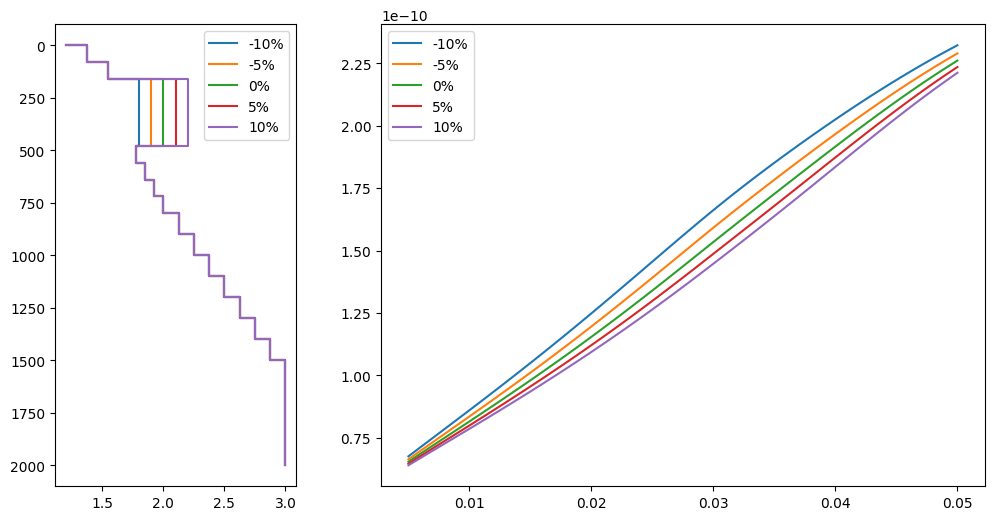

In [39]:
d_interp = np.linspace(0, 800, 11).tolist() + np.linspace(800, 2000, 13).tolist()
d_interp = np.array(d_interp)

wdepth = 780
freqs = np.linspace(0.005, 0.05, 50)

fig, ax = plt.subplots(1, 2, figsize=(12, 6), width_ratios=[1, 2.5])

for i in range(disturb.shape[0]):
    vsi = vs * (1 + disturb[i, :])
    vs_interp = np.interp(d_interp, d, vsi)
    THICKNESS = np.diff(d_interp, prepend=0)[1:]
    VS = vs_interp[1:]
    VP = 1.78 * vs_interp[1:]  # Assuming a constant ratio for VP
    RHO = np.full_like(vs_interp, 2.0)[1:]  # Assuming a constant density

    ax[0].step(vs_interp, d_interp, label=f"{disturb[i, 3] * 100:.0f}%", where='post')

    model = np.vstack([THICKNESS, VS, VP, RHO]).T
    ncomp_i = ncomp_fortran_batch(wdepth, freqs, model)
    ax[1].plot(freqs, ncomp_i, label=f"{disturb[i, 3] * 100:.0f}%")

ax[0].invert_yaxis()
ax[0].legend()
ax[1].legend()

